# Практическая работа №2: Исследование подгрупп сетей. Сети аффилированности

Выполнил студент гр. 4385 Никитин Сергей Вадимович. Вариант №7.

## Цель работы

Овладеть навыками работы с математическими пакетами для исследования подгрупп в социальных сетях, а также моделирования, отображения и анализа сетей аффилированности.

## Основные теоретические положения

### Определения

- **Точка сочленения** - вершина, при удалении которой увеличивается число компонент связности графа.
- **Мост** - ребро, при удалении которого увеличивается число компонент связности графа.

### Мера централизации

**Централизация группы** - количественная мера, характеризующая степень неоднородности (изменчивости) центральности акторов в сети.

Общая формула нормированной централизации:
$$C_A = \frac{\sum_{i=1}^{g} \left(C_A(n^*) - C_A(n_i)\right)}{\max \sum_{i=1}^{g} \left(C_A(n^*) - C_A(n_i)\right)}$$
где $C_A(n_i)$ — центральность $i$-го узла, $C_A(n^*) = \max_i C_A(n_i)$ — максимальное значение центральности в группе, $g$ - число узлов.

- **Централизация по степени:**
  $$C_D = \frac{\sum_{i=1}^{g} \left(C_D(n^*) - C_D(n_i)\right)}{(g - 1)(g - 2)}$$
- **Централизация по близости:**
  $$C_C = \frac{\sum_{i=1}^{g} \left(C'_C(n^*) - C'_C(n_i)\right)}{(g - 2)(g - 1) / (2g - 3)}$$
- **Централизация по посредничеству:**
  $$C_B = \frac{\sum_{i=1}^{g} \left(C'_B(n^*) - C'_B(n_i)\right)}{g - 1}$$

### $k$-ядро

- **$k$-ядро** - максимальный индуцированный подграф, в котором степень каждой вершины не меньше $k$ внутри этого подграфа. Его получают последовательным удалением вершин со степенью меньше $k$, пока таких вершин не останется.
- **Число ядра (coreness)** вершины - наибольшее значение $k$, при котором вершина входит в $k$-ядро. Вершины с большим числом ядра принадлежат к более плотной центральной части сети.

### Сети аффилированности

- **Сеть аффилированности** - сеть, в которой связи между участниками формируются на основе членства в общих группах или совместного участия в событиях.
- В сети заданы два непересекающихся множества вершин: набор акторов $M = \{n_1, n_2, \dots, n_g\}$ и набор событий $N = \{m_1, m_2, \dots, m_h\}$. Связи возможны только между элементами из $M$ и $N$, а связи внутри $M$ и внутри $N$ отсутствуют.

#### Представление сетей аффилированности

- **Матрица аффилированности (инцидентности)** $A = \{a_{ij}\}$ размера $g \times h$:
  $$a_{ij} = \begin{cases} 1, & \text{если актор } i \text{ связан с событием } j, \\ 0, & \text{иначе.} \end{cases}$$
- **Двудольный граф (биграф)** - граф, множество вершин которого разбито на два непересеющихся подмножества ($M$ и $N$), а каждое ребро соединяет вершину из $M$ с вершиной из $N$.
- **Гиперграф** - обобщение графа, в котором одно ребро (гиперребро) может соединять произвольное подмножество вершин, а не только пару.

#### Одномодальные проекции

- Количество событий, в которых совместно участвуют акторы $i$ и $j$:
  $$x_{ij}^M = \sum_{k=1}^{h} a_{ik} a_{jk}$$
  Эти значения образуют симметричную **матрицу совместного участия акторов** $X^M = A A^T$ размера $g \times g$.
- Количество акторов, участвующих одновременно в событиях $k$ и $l$:
  $$x_{kl}^N = \sum_{i=1}^{g} a_{ik} a_{il}$$
  Эти значения образуют симметричную **матрицу перекрытия событий** $X^N = A^T A$ размера $h \times h$.

#### Свойства сети аффилированности

- **Степень участия актора** (количество событий, с которыми связан актор $i$):
  $$d(n_i) = \sum_{j=1}^{h} a_{ij}$$
- **Среднее количество событий** на одного актора:
  $$\bar{d}_M = \frac{1}{g} \sum_{i=1}^{g} d(n_i)$$
- **Размер события** (количество акторов, связанных с событием $j$):
  $$d(m_j) = \sum_{i=1}^{g} a_{ij}$$
- **Средний размер события** (среднее количество акторов на одно событие):
  $$\bar{d}_N = \frac{1}{h} \sum_{j=1}^{h} d(m_j)$$
- **Плотность сети совместного участия акторов:**
  $$\Delta_M = \frac{2 L_M}{g(g - 1)}$$
  где $L_M$ - число ненулевых связей между парами акторов.
- **Плотность сети перекрытия событий:**
  $$\Delta_N = \frac{2 L_N}{h(h - 1)}$$
  где $L_N$ - число ненулевых связей между парами событий.
- **Диаметр сети аффилированности** - длина самой длинной кратчайшей цепи между любой парой достижимых вершин (акторов и/или событий) в биграфе.

#### Меры ассоциации событий

Для пары событий $k$ и $l$ строятся частоты совместной встречаемости по всем $g$ акторам:
- $n_{11}$ - число акторов, участвующих в $k$ и $l$;
- $n_{10}$ - число акторов, участвующих в $k$, но не в $l$;
- $n_{01}$ - число акторов, участвующих в $l$, но не в $k$;
- $n_{00}$ - число акторов, не участвующих ни в $k$, ни в $l$.

- **Отношение шансов:**
  $$\theta_{kl} = \frac{n_{11} \cdot n_{00}}{n_{10} \cdot n_{01}}$$
- **Логарифм отношения шансов:**
  $$L_{kl} = \ln(\theta_{kl})$$
  При наличии нулевых ячеек в таблице сопряжённости к каждой частоте добавляется поправка Холдейна–Энскомба $+0{,}5$, чтобы избежать значений `Inf` и `-Inf`.

## Постановка задачи
С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей на предмет подгрупп. Провести исследование сети аффилированности CEO. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы


In [43]:
library(igraph)
library(sna)
library(intergraph)

In [17]:
## 1.
## Импорт данных из текстовых файлов с разделителями возможен при 
## помощи команды read.table(), функции, которая сохраняет данные 
## в виде таблицы.
## 3.1.2 (34) Дуглас
## as.sociomatrix(net1)


flor_df <- read.csv("florentine_business.csv", comment.char = "#")
flor_mat <- as.matrix(flor_df)
rownames(flor_mat) <- colnames(flor_mat)

In [18]:
## Чтобы создать объект-сеть, нужно вызвать одноименную функцию network().
## Эта cфункция имеет много параметров, но чаще всего ее используют для того, чтобы 
## cпередать ей реляционные данные – обычно в виде матрицы смежности или списка ребер. 
## 3.2.1 (33) Дуглас
##   directed = TRUE - ребра.интерпретируются.как.направленные
## net1 <- network(netmat1,matrix.type="adjacency")



flor_net <- network(flor_mat, matrix.type = "adjacency", directed = FALSE)

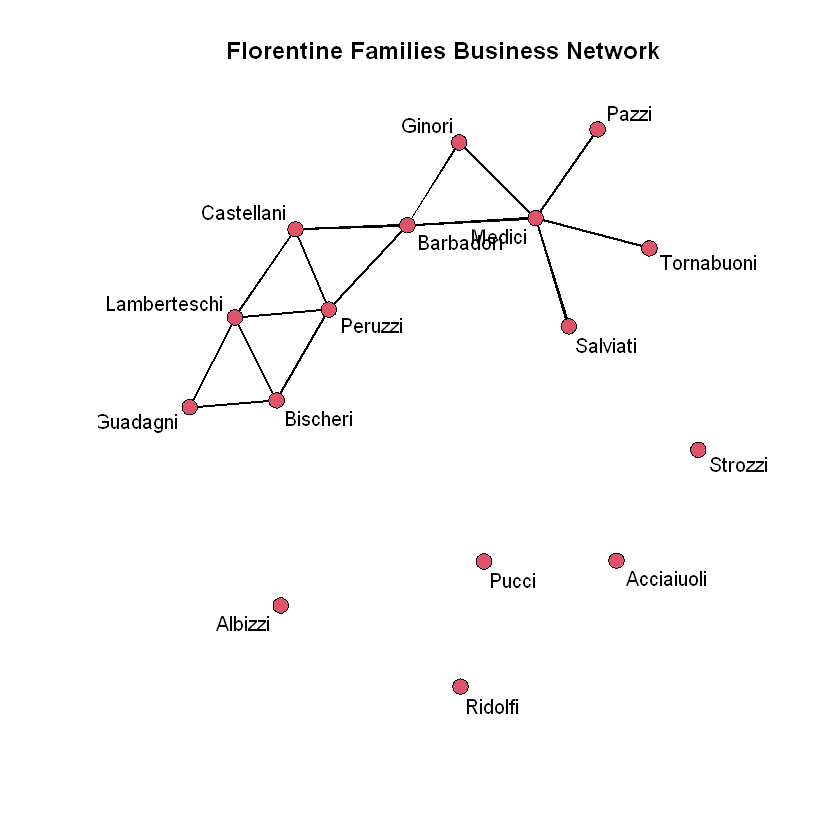

In [19]:
## Визуализация сети в statnet осуществляется с помощью двух тесно связанных 
## между собой функций plot и gplot. Последняя предлагает большее количество 
## алгоритмов укладки, таким образом, она, возможно, будет более полезной. Чтобы 
## использовать тот или иной алгоритм укладки, просто задайте соответствующую укладку. 
## 4.3 (59 - 60) Дуглас

## op <- par(mar = c(0,0,4,0),mfrow=c(1,2))
## gplot(Moreno,gmode="graph",mode="random",
##      vertex.cex=1.5,main="Случайная укладка")
## gplot(Moreno,gmode="graph",mode="fruchtermanreingold",
##      vertex.cex=1.5,main="Фрюхтерман-Рейнгольд")






gplot(flor_net, gmode = "graph", mode = "fruchtermanreingold",
      displaylabels = TRUE, vertex.cex = 0.67,
      main = "Florentine Families Business Network")

В сети деловых связей флорентийских семей 16 вершин: 5 семей изолированы (`Acciaiuoli`, `Albizzi`, `Pucci`, `Ridolfi`, `Strozzi`), остальные 11 образуют одну связную компоненту.

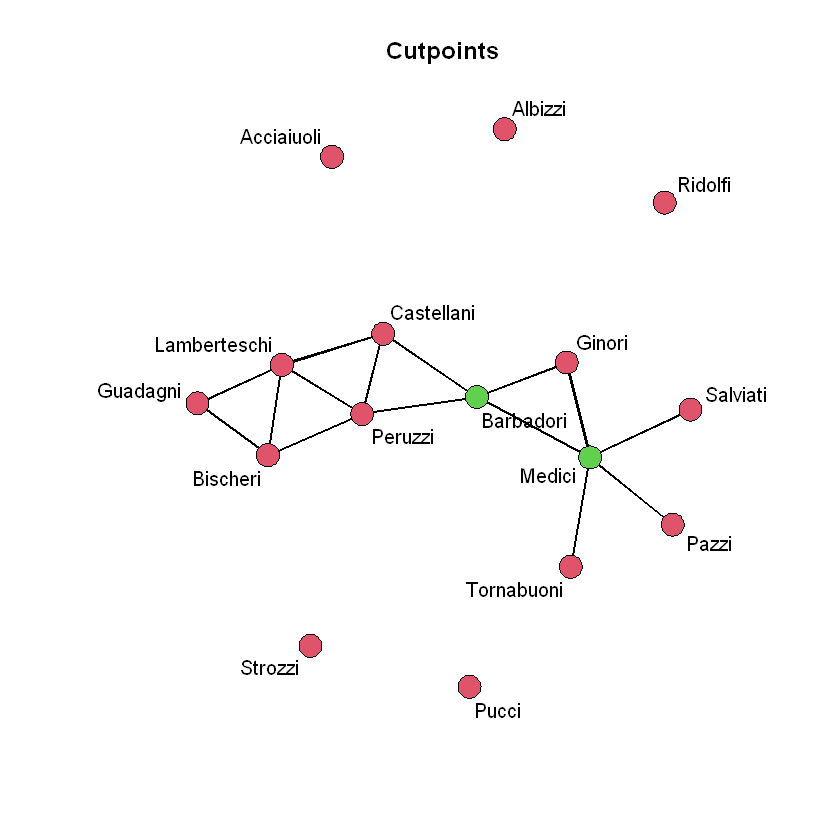

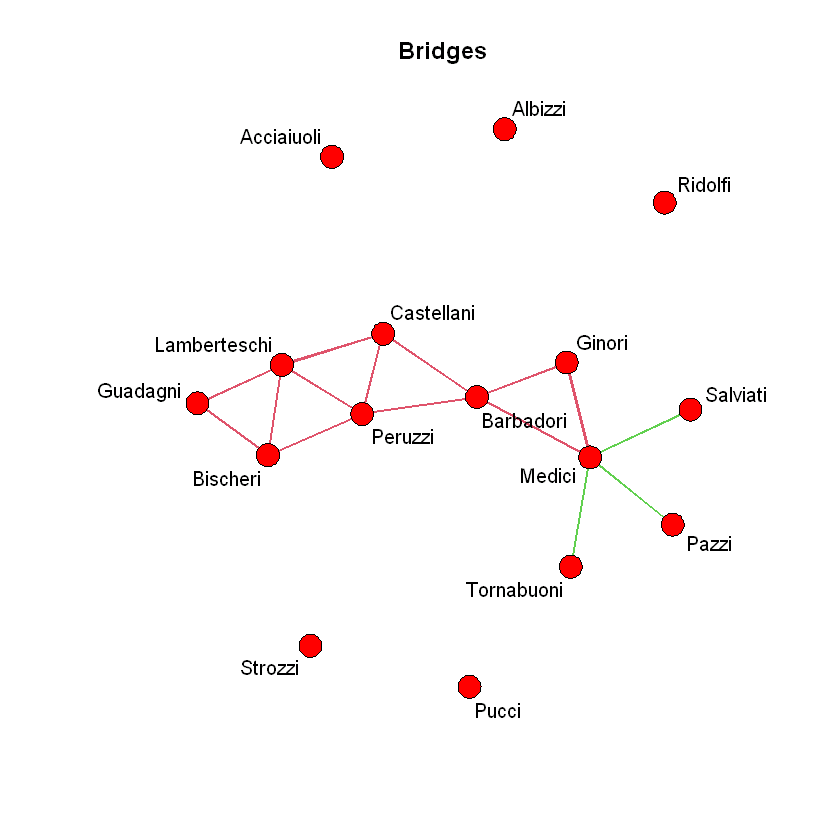

In [20]:
## 2.



## 7.3 (111 - 113) Дуглас
## Для быстрого определения любых точек сочленения в сети вы можете воспользоваться функцией cutpoint() из комплекта пакетов statnet. 
## cpnet <- cutpoints(net,mode="graph",
##                   return.indicator=TRUE)
## mycoord <- gplot(net,gmode="graph",
## vertex.cex=1.5)
## gplot(net,gmode="graph",vertex.col=cpnet+2,
## coord=mycoord,
##      jitter=FALSE,displaylabels=TRUE)
cpnet <- cutpoints(flor_net, mode = "graph", return.indicator = TRUE)
mycoord <- gplot(flor_net, gmode = "graph", displaylabels = TRUE,
                 vertex.col = cpnet + 2, main = "Cutpoints")




## Мосты (bridges) – это ребра, эквивалентные точкам сочленения. Мост – это 
## ребро, при удалении которого одна компонента разделяется на две. В statnet нет 
## функции для определения мостов, но довольно просто создать функцию, которая 
## позволит найти мосты. Эта функция берет направленную или ненаправленную 
## сеть в statnet и исследует каждую связь (она проверяет, происходит ли при удалении связи увеличение числа компонент).
##Функция возвращает логический вектор длиной, равной количеству связей, указывая, какие связи являются мостами.


## bridges <- function(dat,mode="graph",
##                    connected=c("strong", "weak")) {
##  e_cnt <- network.edgecount(dat)
##  if (mode == "graph") {
##    cmp_cnt <- components(dat)
##    b_vec <- rep(FALSE,e_cnt)
##    for(i in 1:e_cnt){
##      dat2 <- dat
##      delete.edges(dat2,i)
##      b_vec[i] <- (components(dat2) != cmp_cnt)
##       }
##  }
##  else {
##    cmp_cnt <- components(dat,connected=connected)
##    b_vec <- rep(FALSE,e_cnt)
##    for(i in 1:e_cnt){
##      dat2 <- dat
## delete.edges(dat2,i)
##      b_vec[i] <- (components(dat2,connected=connected)
##        != cmp_cnt)
##     }
##  }
## return(b_vec)
##}

bridges <- function(dat, mode = "graph",
                    connected = c("strong", "weak")) {
  e_cnt <- network.edgecount(dat)
  if (mode == "graph") {
    cmp_cnt <- components(dat)
    b_vec <- rep(FALSE, e_cnt)
    for (i in 1:e_cnt) {
      dat2 <- dat
      delete.edges(dat2, i)
      b_vec[i] <- (components(dat2) != cmp_cnt)
    }
  } else {
    cmp_cnt <- components(dat, connected = connected)
    b_vec <- rep(FALSE, e_cnt)
    for (i in 1:e_cnt) {
      dat2 <- dat
      delete.edges(dat2, i)
      b_vec[i] <- (components(dat2, connected = connected) != cmp_cnt)
    }
  }
  return(b_vec)
}


## Эта сводка показывает нам, что существуют три связи, которые являются мостами. Кроме того, мы можем использовать функцию bridges так же, как и функцию 
## cutpoints, чтобы показать на графике, какие ребра являются мостами (рис. 7.8).
## brnet <- bridges(net)
## gplot(net,gmode="graph",vertex.col="red",
##          edge.col=brnet+2, coord=mycoord, 
##          jitter=FALSE,displaylabels=TRUE)


brnet <- bridges(flor_net)
gplot(flor_net, gmode = "graph", vertex.col = "red",
      edge.col = brnet + 2, coord = mycoord,
      jitter = FALSE, displaylabels = TRUE, main = "Bridges")

В сети найдены 2 точки сочленения (`Barbadori` и `Medici`) и 1 мост (`Medici - Barbadori`). При удалении любой из этих вершин или ребра-моста основная компонента распадается на отдельные части.

In [21]:
## 3.
## 7.2.1 - 7.2.3 (103 - 107) Дуглас
## Таким образом, центральность по степени (degree centrality) – это просто степень каждого узла.
## В первый раз мы рассказывали о степени узла в главе 2. Степень узла – это количество связей,
## которые соединяют данный узел с другими узлами сети.

## Это приводит нас к понятию центральность по близости (closeness centrality), где 
## более важными узлами считаются узлы, наиболее близкие к остальным узлам сети. 

## Центральность по посредничеству (betweenness centrality) характеризует, насколько 
## важную роль данный узел играет на пути «между» парами других узлов сети, в том 
## смысле, что пути между другими узлами должны проходить через данный узел. 
## Узел с наибольшим значением центральности по посредничеству является важным, 
## потому что данный узел позволяет отслеживать или контролировать поток информации в сети.

## Узлы, которые идентифицированы как узлы с высокими значениями центральности по 
## собственному вектору (eigenvector centrality), вероятно, другими метриками также 
## будут идентифицированы как центральные, особенно если эти метрики тесно связаны с центральностью по собственному вектору 
## (например, индекс силы Боначича). 

## cd <- centralization(Bali,degree)
## cc <- centralization(Bali,closeness)
##cb <- centralization(Bali,betweenness)



c_deg <- centralization(flor_net, degree, mode = "graph")
c_clo <- centralization(flor_net, closeness, mode = "graph", cmode = "suminvundir")
c_bet <- centralization(flor_net, betweenness, mode = "graph")
c_eig <- centralization(flor_net, evcent, mode = "graph")

cat("Degree centralization:", c_deg, "\n")
cat("Closeness centralization:", c_clo, "\n")
cat("Betweenness centralization:", c_bet, "\n")
cat("Eigenvector centralization:", c_eig, "\n")

Degree centralization: 0.2380952 
Closeness centralization: 0.4774603 
Betweenness centralization: 0.2057143 
Eigenvector centralization: 0.4663812 


Показатели централизации невысокие: по степени - `0.238`, по посредничеству - `0.206`, по собственному вектору - `0.466`. Для расчёта централизации по близости (`0.477`) использован параметр `cmode = "suminvundir"`, так как в графе присутствуют изолированные вершины.

coreness
0 1 2 
5 3 8 

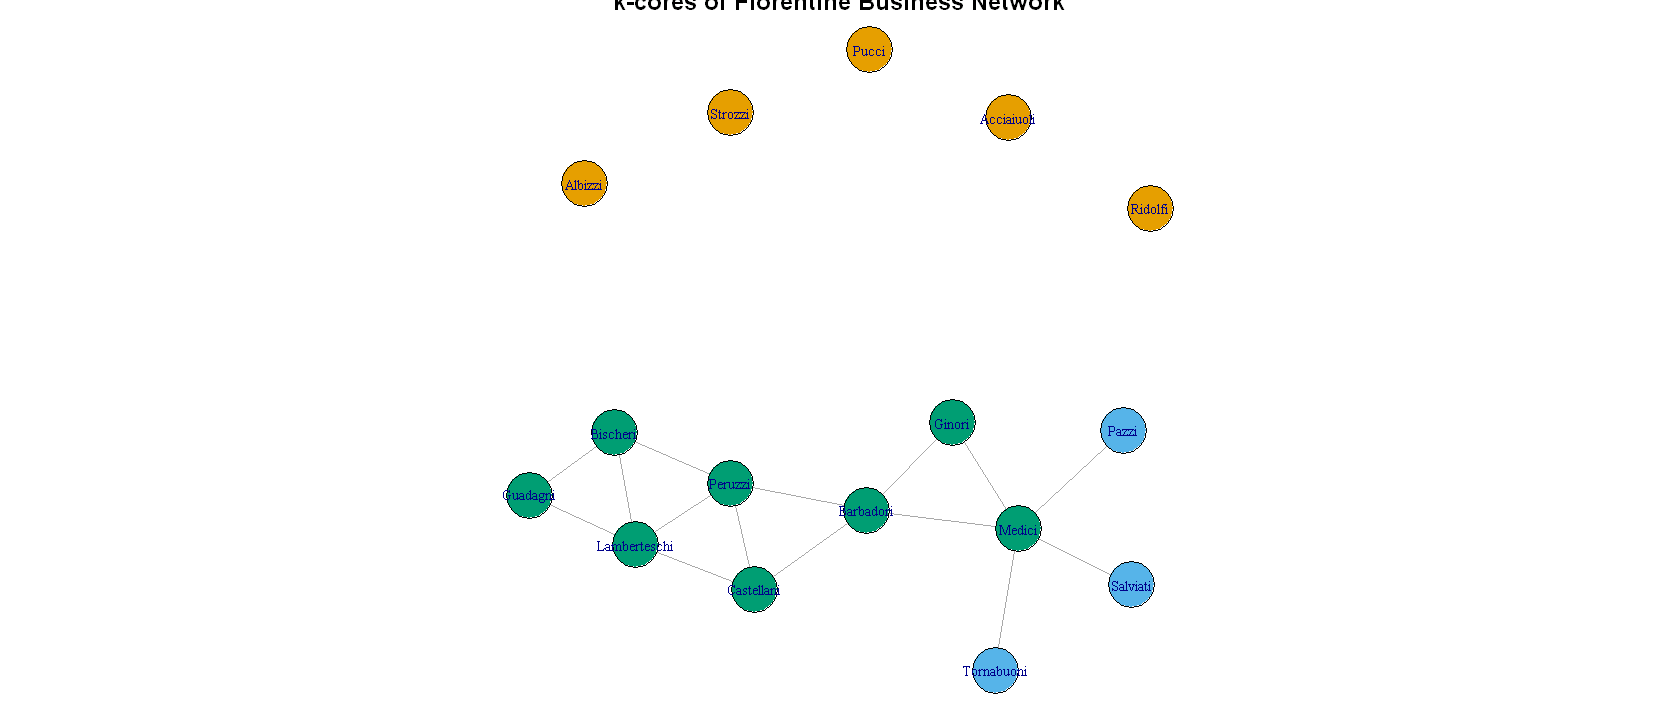

In [47]:
## 4.
## 8.2.2 (120 - 123) Дуглас
## Для определения k-ядерной структуры используется функция graph.coreness.
## Для каждой вершины вычисляется ядро с максимальным k, которому она принадлежит.
## 1-ядро содержит 7 вершин, 2-ядро – 6 вершин, 3-ядро – 2 вершины 
## и т. д. Результаты показывают нам, что k варьирует от 1 до 6. 
## coreness <- graph.coreness(iDHHS)
## table(coreness)

## 3.2.4 (41) Дуглас
## net1igraph <- asIgraph(net1)
## В примере, приведенном ниже, мы преобразуем данные net1 в формат igraph с помощью функции asIgraph.
## Если бы мы хотели выполнить обратное преобразование, то воспользовались бы функцией asNetwork.

## Атрибут цветов вершин используется,
## чтобы задать цвета узлов по умолчанию. Здесь мы добавляем 1 к значениям 
## k-ядер, сохраненным в векторе coreness, чтобы быстро и эффективно подобрать 
## различные цвета для каждого k-ядра, а также избежать черного цвета (рис. 8.4).
## Vname <- get.vertex.attribute(iDHHS,name='vertex.names',
##                              index=V(iDHHS))
## V(iDHHS)$name <- Vname
## V(iDHHS)$color <- coreness + 1
## op <- par(mar = rep(0, 4))
## plot(iDHHS,vertex.label.cex=0.8)
## par(op)
## Чтобы упростить интерпретацию, мы можем присвоить узлам метки, где будут указаны k-ядра, которым они принадлежат.
## iDHHS <- asIgraph(DHHS)
## graph.density(iDHHS)
##  ## [1] 0.312
## iDHHS <- subgraph.edges(iDHHS,E(iDHHS)[collab > 2])
## graph.density(iDHHS)
## Для определения k-ядерной структуры используется функция graph.coreness.
## Для каждой вершины вычисляется ядро с максимальным k, которому она принадлежит. 
## 1-ядро содержит 7 вершин, 2-ядро – 6 вершин, 3-ядро – 2 вершины и т. д.
## Результаты показывают нам, что k варьирует от 1 до 6. 
## coreness <- graph.coreness(iDHHS)
## table(coreness)



flor_ig <- asIgraph(flor_net)
Vname <- igraph::get.vertex.attribute(flor_ig, name = 'vertex.names', index = V(flor_ig))
V(flor_ig)$name <- Vname

coreness <- igraph::graph.coreness(flor_ig)
table(coreness)

V(flor_ig)$color <- coreness + 1
op <- par(mar = rep(0, 4))
plot(flor_ig, vertex.label.cex = 0.7, main = "k-cores of Florentine Business Network")
par(op)


Разложение на $k$-ядра показывает: 8 семей входят в 2-ядро (`Barbadori`, `Bischeri`, `Castellani`, `Ginori`, `Guadagni`, `Lamberteschi`, `Medici`, `Peruzzi`), 3 семьи имеют число ядра 1 (`Pazzi`, `Salviati`, `Tornabuoni`), а 5 изолированных вершин — 0.

[1] 0.3111111

[1] 0.3644444

[1] 0.3644444

  Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
           1            2            3            3            3            4 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
           3            3            4            4            3            5 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
           6            4            7            4 

  Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
           1            2            3            7            7            3 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
           7            7            3            3            7            4 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
           5            3            6            3 

  Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
           3            4            1            2            2            1 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
           2            2            1            1            2            5 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
           6            1            7            1 

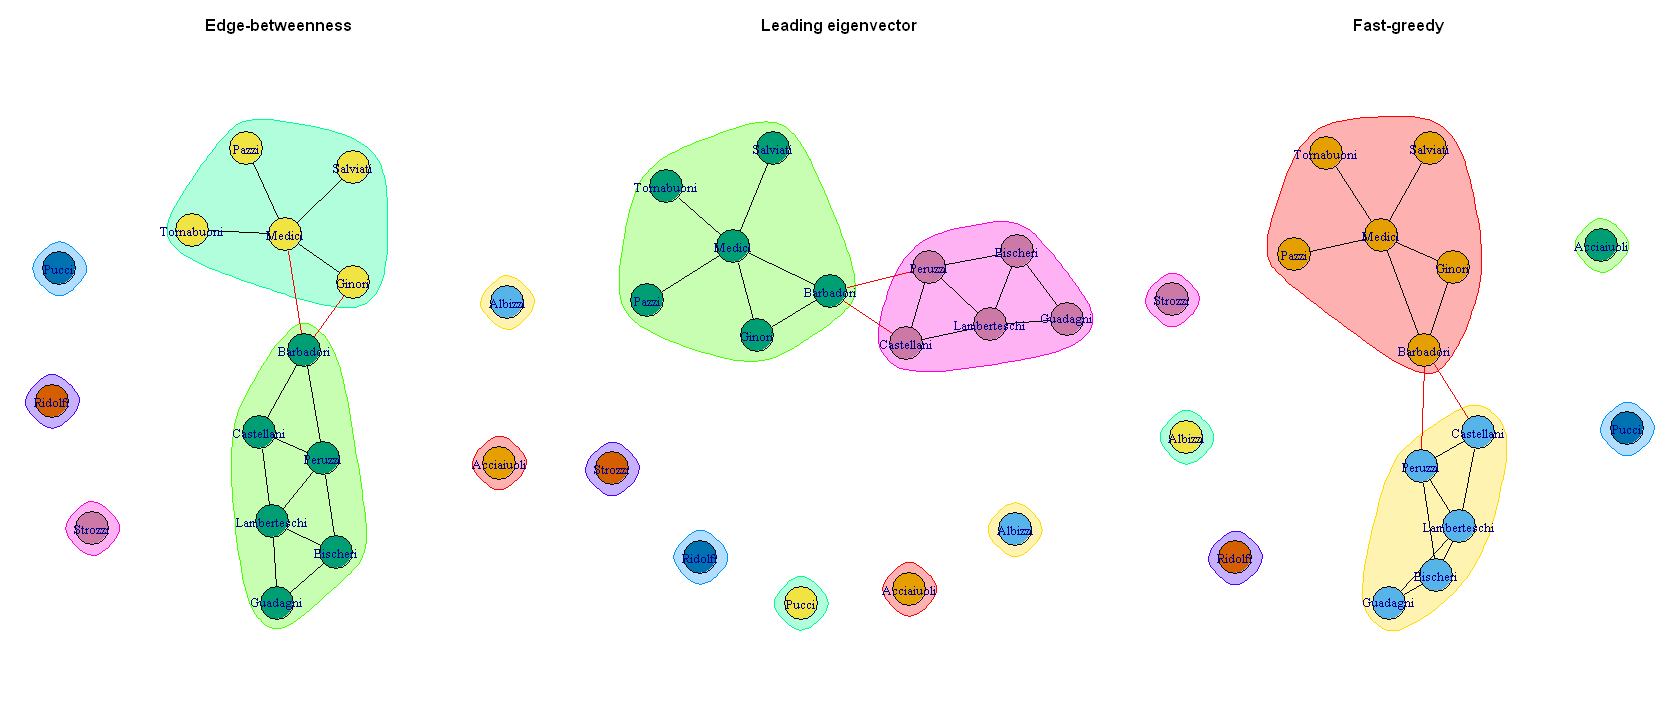

In [45]:
## 5.
## Важная характеристика сети, используемая во многих алгоритмах обнаружения 
## сообществ, – это модулярность (modularity). Модулярность характеризует струк
## туру сети, в частности степень кластеризации узлов, когда внутри кластера наблю
## дается много узлов (высокая плотность), а между кластерами мало узлов (низкая 
## плотность) (Newman 2006). Модулярность можно использовать в исследователь
## ских целях, когда мы с помощью того или иного алгоритма пытаемся максими
## зировать модулярность и выполнить классификацию узлов,  которая наилучшим 
## образом объясняет существующую кластеризацию. С другой стороны, модуляр
## ность можно использовать для описания сети, когда показатель модулярности 
## вычисляется для любой переменной группировки узлов. Например, для сети дру
## жеских контактов аналитик может вычислить модулярность по полу участников сети.
## Таким образом, модулярность показывает, в какой степени пол участников 
## сети объясняет наблюдаемую кластеризацию среди друзей. Показатель модулярности определяется как разница между долей связей внутри группы и ожидаемой 
## долей связей, если бы связи были размещены случайно. Показатель модулярности 
## может принимать значения в диапазоне от –1/2 до +1. Чем выше показатель, тем больше уровень кластеризации сети в соответствии с данной группировкой узлов. 
## 8.3.1 (125 - 126) Дуглас



## Edge-betweenness.(Посредничество ребер)
## Направленных сетей - да
## Взвешенных сетей - да
## Сетей из нескольких компонент - да
## 1 В качестве синонима также используется термин «промежуточность ребер». – Прим. пер.
ceb <- cluster_edge_betweenness(flor_ig)

## Leading eigenvector (Главный собственный вектор)
## Направленных сетей - нет
## Взвешенных сетей - нет
## Сетей из нескольких компонент - да
cle <- cluster_leading_eigen(flor_ig)

## Fast-greedy (Быстро работающий жадный)
## Направленных сетей - нет
## Взвешенных сетей - да
## Сетей из нескольких компонент - да
cfg <- cluster_fast_greedy(flor_ig)



modularity(ceb)
modularity(cle)
modularity(cfg)
## 8.3.2 (127 - 133) Дуглас

membership(ceb)
membership(cle)
membership(cfg)


##  op <- par(mfrow=c(3,2),mar=c(3,0,2,0))
##  plot(ceb, iBali,vertex.label=V(iBali)$role,
##     main="Edge Betweenness")
##  plot(cfg, iBali,vertex.label=V(iBali)$role,
##     main="Fastgreedy")
##  plot(clp, iBali,vertex.label=V(iBali)$role,
##     main="Label Propagation")
##  plot(cle, iBali,vertex.label=V(iBali)$role,
##     main="Leading Eigenvector")
##  plot(cs, iBali,vertex.label=V(iBali)$role,
##     main="Spinglass")
##  plot(cw, iBali,vertex.label=V(iBali)$role,
##     main="Walktrap")
##  par(op)


options(repr.plot.width = 14, repr.plot.height = 6)
op <- par(mfrow = c(1, 3), mar = c(1, 1, 3, 1))
plot(ceb, flor_ig, main = "Edge-betweenness")
plot(cle, flor_ig, main = "Leading eigenvector")
plot(cfg, flor_ig, main = "Fast-greedy")
par(op)

- **Edge-betweenness** - пошагово удаляет рёбра с наибольшим посредничеством, разделяя сеть на сообщества.
- **Leading eigenvector** - делит граф на подгруппы по знаку компонент главного собственного вектора матрицы модулярности.
- **Fast-greedy** - жадно объединяет вершины и группы так, чтобы на каждом шаге максимально росла модулярность.

Все три алгоритма (Edge-betweenness, Leading eigenvector, Fast-greedy) разбили сеть на 7 сообществ с близкой модулярностью (`0.311` и `0.364`): 5 изолированных семей выделяются отдельно, а основная компонента делится на две подгруппы.

In [27]:
## 6.
## 9.1.1 (135 - 136) Дуглаc
## 9.1.2 (137 - 138) Дуглас
## Матрица инцидентности, наоборот, является прямоугольной матрицей nxg с двумя различными измерениями: акторами и группами.
## library(igraph)
## bn <- graph.incidence(aff.df)
## plt.x <- c(rep(2,6),rep(4,4))
## plt.y <- c(7:2,6:3)
## lay <- as.matrix(cbind(plt.x,plt.y))

## Кабаков (149)
## paste(..., sep=””)
## Объединяет элементы, разделяя их указанным символом.
## paste(“x”, 1:3, sep=””) возвращает c(“x1”, “x2”, “x3”).
## paste(“x”,1:3, sep=”M”) возвращает c(“xM1”,“xM2” “xM3”).
## paste(“Today is”, date()) возвращает
## Today is Thu Jun 25 14:17:32 2011

ceo_mat <- as.matrix(read.csv("ceo.csv", header = FALSE, comment.char = "#"))
rownames(ceo_mat) <- paste("CEO", 1:nrow(ceo_mat), sep = "")
colnames(ceo_mat) <- paste("Club", 1:ncol(ceo_mat), sep = "")
ceo_mat

ceo_bn <- graph.incidence(ceo_mat)
ceo_bn

,Club1,Club2,Club3,Club4,Club5,Club6,Club7,Club8,Club9,Club10,Club11,Club12,Club13,Club14,Club15
CEO1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0
CEO2,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0
CEO3,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
CEO4,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1
CEO5,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0
CEO6,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0
CEO7,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0
CEO8,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0
CEO9,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0
CEO10,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0


IGRAPH 3040919 UN-B 41 98 -- 
+ attr: type (v/l), name (v/c)
+ edges from 3040919 (vertex names):
 [1] CEO1 --Club3  CEO1 --Club4  CEO1 --Club9  CEO2 --Club3  CEO2 --Club5 
 [6] CEO2 --Club7  CEO3 --Club3  CEO3 --Club12 CEO4 --Club2  CEO4 --Club3 
[11] CEO4 --Club15 CEO5 --Club3  CEO5 --Club13 CEO5 --Club14 CEO6 --Club2 
[16] CEO6 --Club3  CEO6 --Club14 CEO7 --Club3  CEO7 --Club4  CEO7 --Club10
[21] CEO7 --Club11 CEO8 --Club4  CEO8 --Club7  CEO8 --Club10 CEO9 --Club1 
[26] CEO9 --Club4  CEO9 --Club8  CEO9 --Club10 CEO10--Club3  CEO10--Club9 
[31] CEO11--Club2  CEO11--Club3  CEO11--Club9  CEO12--Club4  CEO12--Club7 
[36] CEO13--Club3  CEO13--Club4  CEO13--Club5  CEO13--Club9  CEO14--Club2 
+ ... omitted several edges

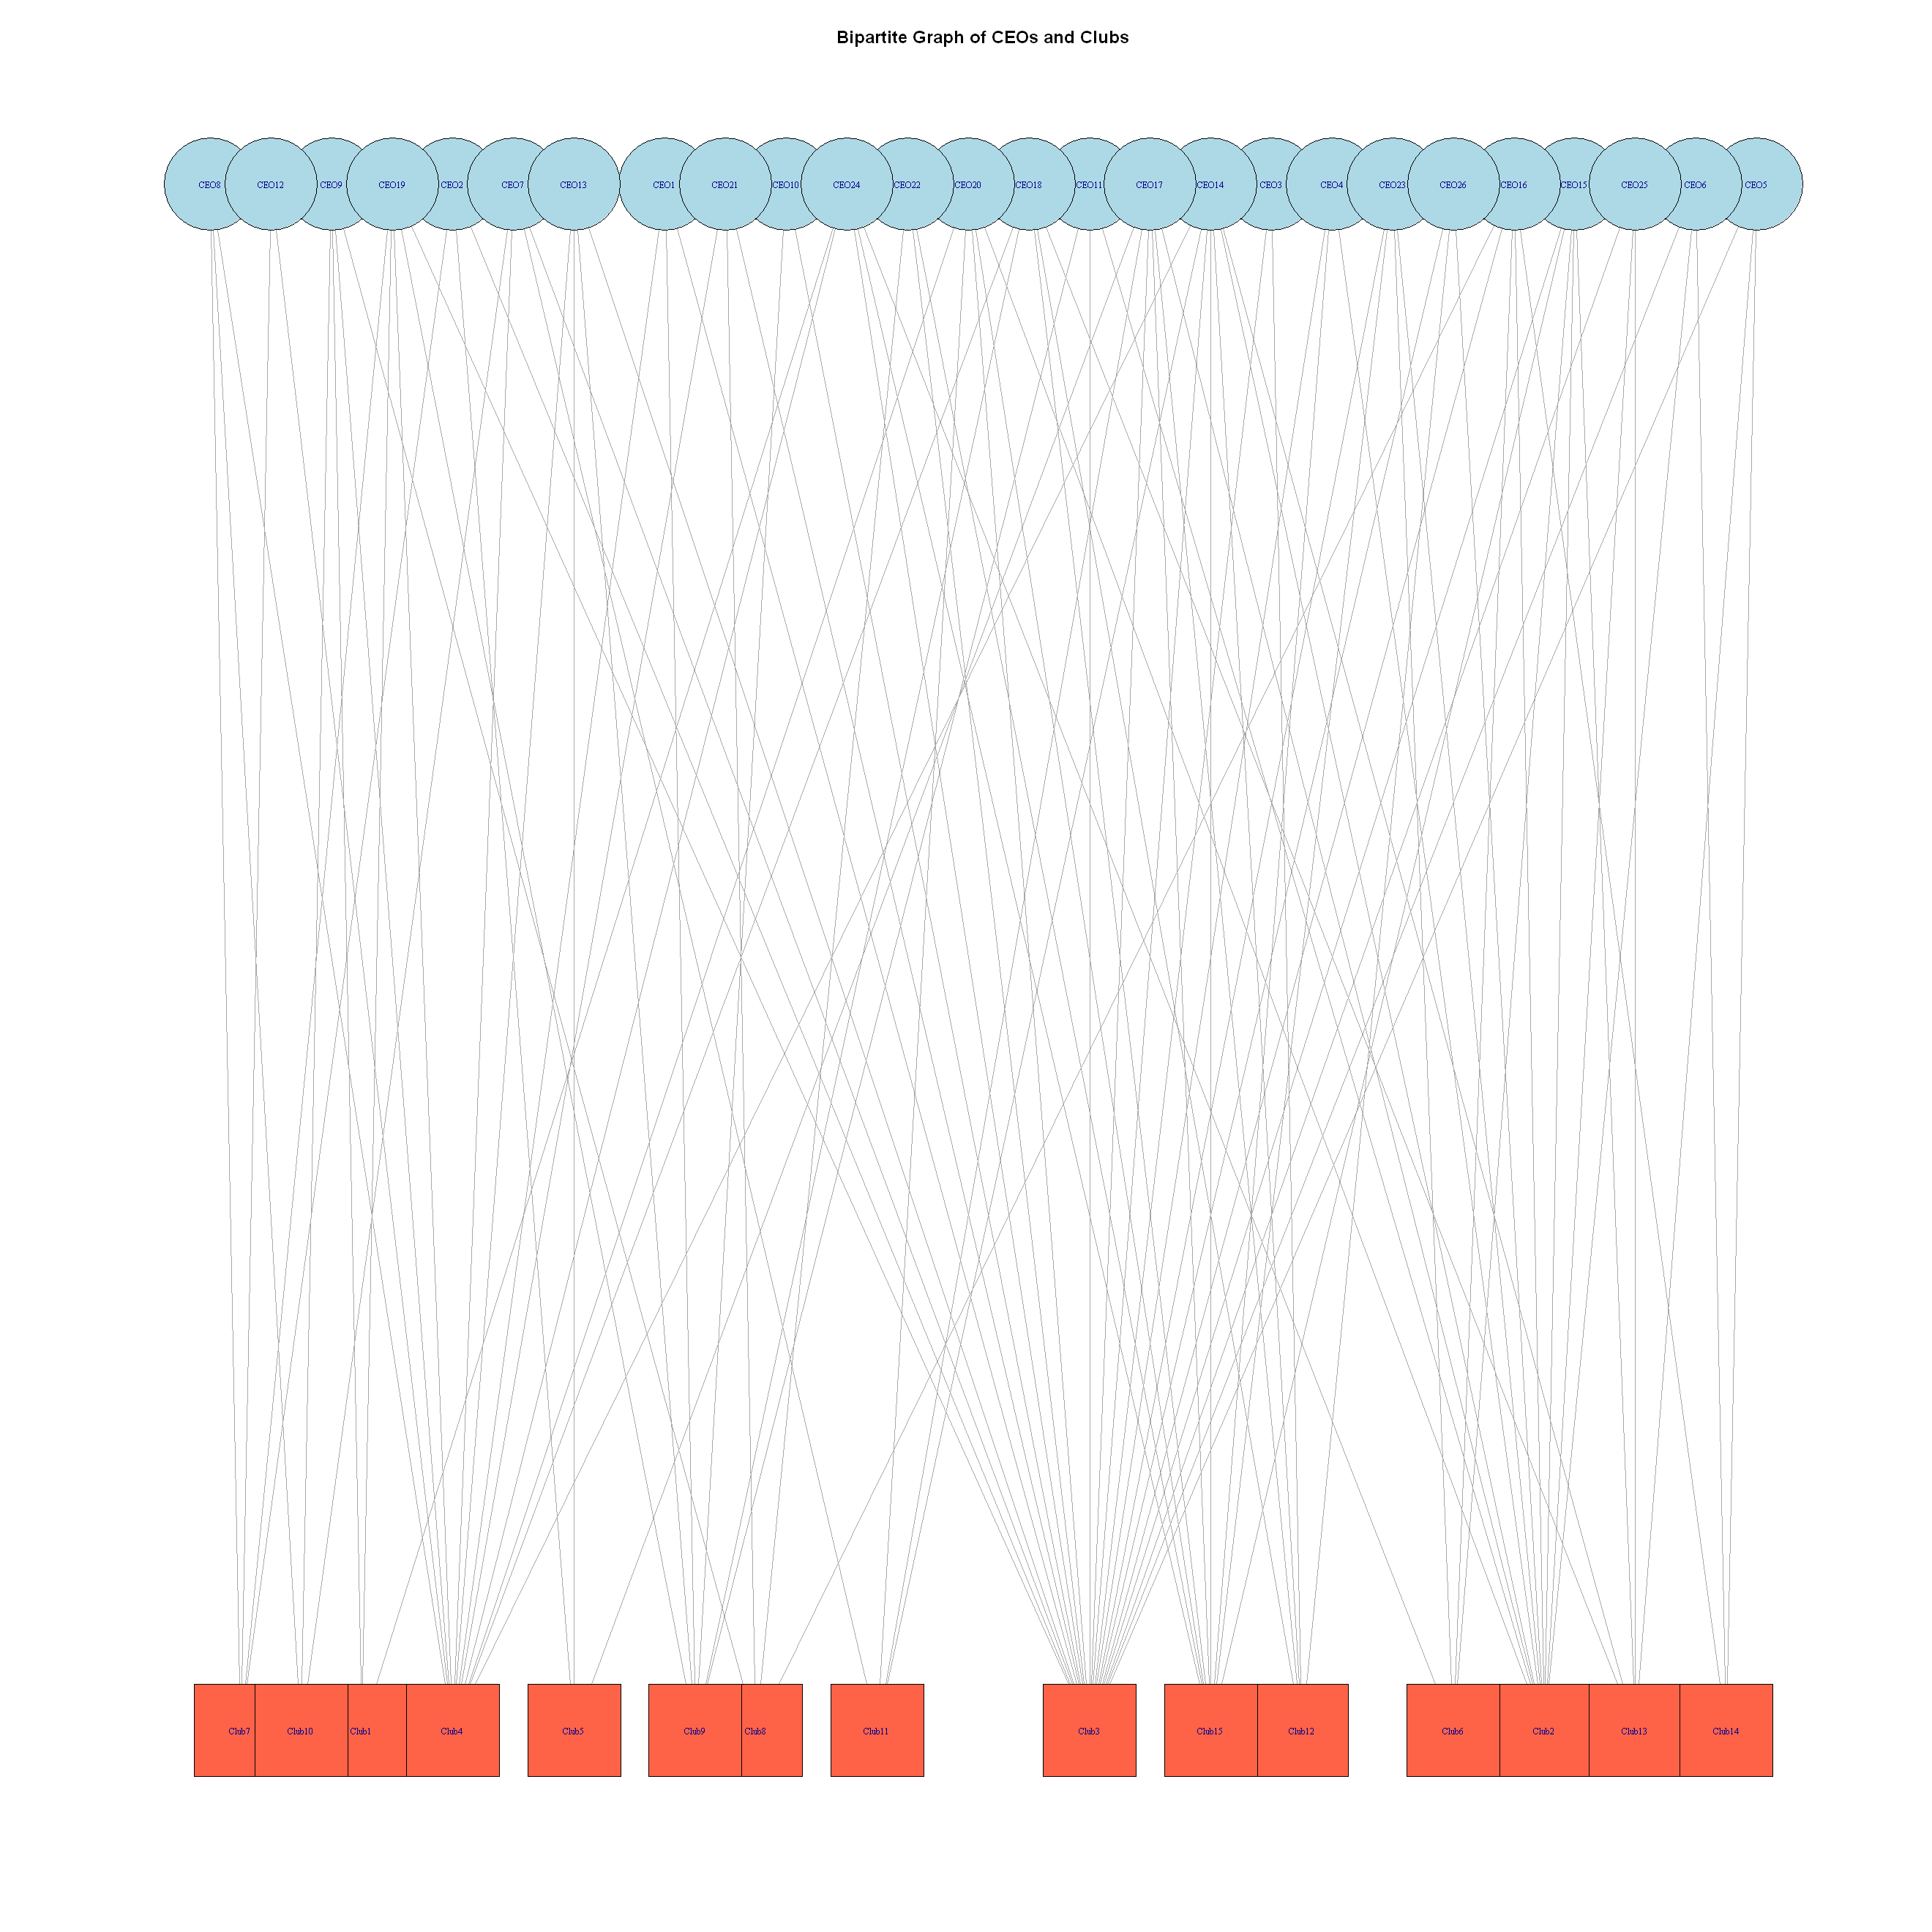

In [66]:
## 7.

## 9.1.2 (136 - 137) Дуглаc
## shapes <- c("circle","square")
## colors <- c("blue","red")
## plot(bn,vertex.color=colors[V(bn)$type+1],
##     vertex.shape=shapes[V(bn)$type+1],
##     vertex.size=10,vertex.label.degree=-pi/2,
##     vertex.label.dist=1.2,vertex.label.cex=0.9,
##     layout=lay)

shapes <- c("circle", "square")
colors <- c("lightblue", "tomato")
options(repr.plot.width = 22, repr.plot.height = 22)
plot(ceo_bn,
     layout = layout_as_bipartite,
     vertex.color = colors[V(ceo_bn)$type + 1],
     vertex.shape = shapes[V(ceo_bn)$type + 1],
     vertex.size = 12, vertex.label.cex = 0.6,
     main = "Bipartite Graph of CEOs and Clubs")

Матрица инцидентности `ceo_mat` имеет размер `26 × 15`. На её основе построен двудольный граф `ceo_bn` из 41 вершины (26 директоров и 15 клубов) и 98 рёбер.

In [ ]:
##8.

,CEO1,CEO2,CEO3,CEO4,CEO5,CEO6,CEO7,CEO8,CEO9,CEO10,⋯,CEO17,CEO18,CEO19,CEO20,CEO21,CEO22,CEO23,CEO24,CEO25,CEO26
CEO1,0,1,1,1,1,1,2,1,1,2,⋯,1,2,3,2,2,1,1,2,1,1
CEO2,1,0,1,1,1,1,1,1,0,1,⋯,2,0,2,1,1,1,1,1,1,1
CEO3,1,1,0,1,1,1,1,0,0,1,⋯,2,1,1,1,1,1,1,1,1,2
CEO4,1,1,1,0,1,2,1,0,0,1,⋯,3,1,1,3,1,2,3,2,2,2
CEO5,1,1,1,1,0,2,1,0,0,1,⋯,1,1,1,1,1,1,1,1,2,1
CEO6,1,1,1,2,2,0,1,0,0,1,⋯,2,0,1,2,1,1,2,1,2,2
CEO7,2,1,1,1,1,1,0,2,2,1,⋯,2,1,2,3,2,1,1,2,1,1
CEO8,1,1,0,0,0,0,2,0,2,0,⋯,0,1,2,1,1,0,0,1,0,0
CEO9,1,0,0,0,0,0,2,2,0,0,⋯,0,1,2,1,2,1,0,2,0,0
CEO10,2,1,1,1,1,1,1,0,0,0,⋯,1,1,2,1,1,1,1,1,1,1


,Club1,Club2,Club3,Club4,Club5,Club6,Club7,Club8,Club9,Club10,Club11,Club12,Club13,Club14,Club15
Club1,0,0,2,3,0,1,1,1,1,1,0,0,0,0,1
Club2,0,0,11,2,1,3,0,1,1,0,3,3,3,2,6
Club3,2,11,0,8,3,4,2,3,5,1,4,4,4,3,8
Club4,3,2,8,0,1,1,3,2,4,3,3,2,2,0,4
Club5,0,1,3,1,0,0,1,0,1,0,1,1,0,0,1
Club6,1,3,4,1,0,0,0,1,0,0,0,0,1,1,3
Club7,1,0,2,3,1,0,0,0,1,1,0,0,0,0,0
Club8,1,1,3,2,0,1,0,0,0,1,0,0,0,1,1
Club9,1,1,5,4,1,0,1,0,0,0,0,1,1,0,1
Club10,1,0,1,3,0,0,1,1,0,0,1,0,0,0,0


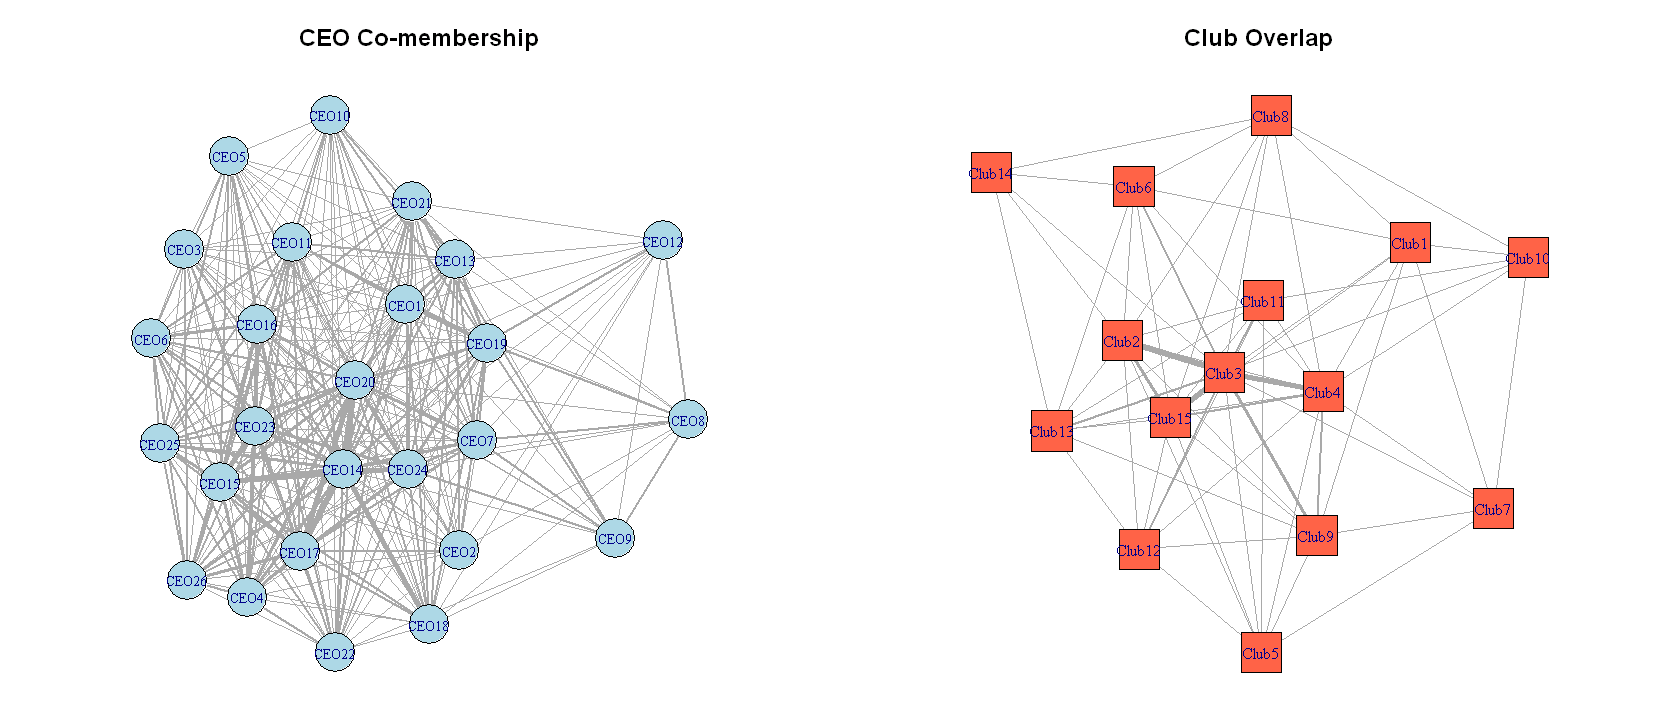

In [50]:
## 9.2.4 (140 - 143) Дуглаc
## Функция bipartite.projection возвращает список из двух объектов-сетей igraph.
## Первая сеть включает прямые связи между узлами первого типа (между студентами),
## а вторая сеть – прямые связи между узлами второго типа (между классами)

## bn.pr <- bipartite.projection(bn)
## bn.pr
## bn.student <- bn.pr$proj1
## bn.class <- bn.pr$proj2
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                
pr <- bipartite.projection(ceo_bn)
net_actors <- pr$proj1
net_events <- pr$proj2

## Матрицу смежности для каждой одномодальной проекции можно получить 
## с помощью функции get.adjacency. В коде, приведенном ниже, обратите внимание на то,
## как задан атрибут ребер weight. Он строит матрицу смежности с числовыми значениями, 
## где значения указывают, какое количество связей соединяет любой из узлов. 
## get.adjacency(bn.student,sparse=FALSE,attr="weight")



mat_actors <- get.adjacency(net_actors, sparse = FALSE, attr = "weight")
mat_events <- get.adjacency(net_events, sparse = FALSE, attr = "weight")

mat_actors
mat_events

##  op <- par(mfrow=c(3,2),mar=c(3,0,2,0))
##  plot(ceb, iBali,vertex.label=V(iBali)$role,
##     main="Edge Betweenness")
##  plot(cfg, iBali,vertex.label=V(iBali)$role,
##     main="Fastgreedy")
##  plot(clp, iBali,vertex.label=V(iBali)$role,
##     main="Label Propagation")
##  plot(cle, iBali,vertex.label=V(iBali)$role,
##     main="Leading Eigenvector")
##  plot(cs, iBali,vertex.label=V(iBali)$role,
##     main="Spinglass")
##  plot(cw, iBali,vertex.label=V(iBali)$role,
##     main="Walktrap")
##  par(op)
## shapes <- c("circle","square")
## colors <- c("blue","red")
## op <- par(mfrow=c(1,2))
## plot(bn.student,vertex.color="blue",
##     vertex.shape="circle",main="Студенты",
##     edge.width=E(bn.student)$weight*2,
##     vertex.size=15,vertex.label.degree=-pi/2,
##     vertex.label.dist=1.2,vertex.label.cex=1)
## plot(bn.class,vertex.color="red",
##     vertex.shape="square",main="Классы",
##     edge.width=E(bn.student)$weight*2,
## Пример: актеры Голливуда как пример сети аффилированности
## 143
##     vertex.size=15,vertex.label.degree=-pi/2,
##     vertex.label.dist=1.2,vertex.label.cex=1)
## par(op)



options(repr.plot.width = 14, repr.plot.height = 6)
op <- par(mfrow = c(1, 2), mar = c(1, 1, 3, 1))
plot(net_actors, vertex.color = "lightblue", vertex.size = 15, vertex.label.cex = 0.7,
     edge.width = E(net_actors)$weight, main = "CEO Co-membership")
plot(net_events, vertex.color = "tomato", vertex.shape = "square", vertex.size = 15,
     vertex.label.cex = 0.8, edge.width = E(net_events)$weight * 0.5, main = "Club Overlap")
par(op)

Построены одномодальные проекции: для директоров (`net_actors`) максимальный вес связи равен 5 (`CEO14 - CEO17`, `CEO14 - CEO20`), а для клубов (`net_events`) максимальное пересечение равно 11 (`Club2 - Club3`).

In [31]:
## 10

## 9.3.1 (146) Дуглаc


## Функция degree позволяет задать вершины для включения в анализ 
## и используется, чтобы выбрать актеров (для которых характеристика узла type 
## имеет значение FALSE).
## table(degree(h1,v=V(h1)[type==FALSE]))

deg_actors <- igraph::degree(ceo_bn, v = V(ceo_bn)[type == FALSE])
deg_actors
mean(deg_actors)


CEO1  CEO2  CEO3  CEO4  CEO5  CEO6  CEO7  CEO8  CEO9 CEO10 CEO11 CEO12 CEO13 
    3     3     2     3     3     3     4     3     4     2     3     2     4 
CEO14 CEO15 CEO16 CEO17 CEO18 CEO19 CEO20 CEO21 CEO22 CEO23 CEO24 CEO25 CEO26 
    7     5     5     6     5     5     5     3     3     4     5     3     3

[1] 3.769231

Степени участия директоров лежат в диапазоне от 2 до 7 клубов, среднее значение составляет `3.77`. Наиболее активны `CEO14` (7 клубов) и `CEO17` (6 клубов).

In [32]:
## 11
## 9.3.1 (146) Дуглаc

## Кабаков 5.2.6 (151)
## Функция mean() вычисляет среднее арифметическое для всех 12 элементов матрицы.

size_events <- igraph::degree(ceo_bn, v = V(ceo_bn)[type == TRUE])
size_events
mean(size_events)

Club1  Club2  Club3  Club4  Club5  Club6  Club7  Club8  Club9 Club10 Club11 
     3     11     22     12      3      4      4      4      6      3      4 
Club12 Club13 Club14 Club15 
     5      5      3      9

[1] 6.533333

Размеры клубов варьируются от 3 до 22 участников, средний размер - `6.53`. Самый крупный клуб - `Club3` (22 участника), далее идут `Club4` (12) и `Club2` (11).

In [34]:
## 12
## 9.3.1 (146) Дуглаc
## Каждый объект из этого списка можно прочитать и обработать как обычный 
## объект-сеть igraph либо внутри списка, либо создав новый объект.
## graph.density(bn.pr$proj1)

graph.density(net_actors)
graph.density(net_events)


[1] 0.8738462

[1] 0.6285714

Плотность сети совместного участия директоров равна `0.874` (связи между CEO очень плотные), а плотность сети перекрытия клубов ниже - `0.629`.

In [41]:
## 13
## 2.4.4 (26) Дуглаc


diameter(ceo_bn)

[1] 5

Диаметр двудольной сети равен 5 - это максимальное кратчайшее расстояние между любой парой вершин в графе.

In [42]:
## 14
## Кабаков (57)
##  mymatrix <- matrix(cells, nrow=2, ncol=2, byrow=TRUE, dimnames=list(rnames, cnames))

h <- ncol(ceo_mat)
odds_mat <- matrix(NA, nrow = h, ncol = h, dimnames = list(colnames(ceo_mat), colnames(ceo_mat)))
log_odds_mat <- odds_mat

for (j in 1:(h - 1)) {
  for (k in (j + 1):h) {
    n11 <- sum(ceo_mat[, j] == 1 & ceo_mat[, k] == 1)
    n10 <- sum(ceo_mat[, j] == 1 & ceo_mat[, k] == 0)
    n01 <- sum(ceo_mat[, j] == 0 & ceo_mat[, k] == 1)
    n00 <- sum(ceo_mat[, j] == 0 & ceo_mat[, k] == 0)

    theta <- ((n11 + 0.5) * (n00 + 0.5)) / ((n10 + 0.5) * (n01 + 0.5))
    odds_mat[j, k] <- theta
    log_odds_mat[j, k] <- log(theta)
  }
}

round(odds_mat, 2)
round(log_odds_mat, 2)

,Club1,Club2,Club3,Club4,Club5,Club6,Club7,Club8,Club9,Club10,Club11,Club12,Club13,Club14,Club15
Club1,NA,0.16,0.28,10.68,0.84,3.51,3.51,3.51,2.02,5.16,0.62,0.48,0.48,0.84,1.09
Club2,NA,NA,9.00,0.14,0.77,3.98,0.11,0.51,0.27,0.16,3.98,2.22,2.22,2.54,4.22
Club3,NA,NA,NA,0.07,1.62,2.19,0.12,0.42,0.73,0.07,2.19,0.57,0.57,1.62,1.37
Club4,NA,NA,NA,NA,0.65,0.43,3.32,1.19,2.65,10.68,3.32,0.78,0.78,0.13,0.91
Club5,NA,NA,NA,NA,NA,0.62,3.51,0.62,2.02,0.84,3.51,2.60,0.48,0.84,1.09
Club6,NA,NA,NA,NA,NA,NA,0.46,2.39,0.28,0.62,0.46,0.35,1.76,3.51,5.92
Club7,NA,NA,NA,NA,NA,NA,NA,0.46,1.36,3.51,0.46,0.35,0.35,0.62,0.16
Club8,NA,NA,NA,NA,NA,NA,NA,NA,0.28,3.51,0.46,0.35,0.35,3.51,0.73
Club9,NA,NA,NA,NA,NA,NA,NA,NA,NA,0.38,0.28,1.00,1.00,0.38,0.40
Club10,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,3.51,0.48,0.48,0.84,0.22


,Club1,Club2,Club3,Club4,Club5,Club6,Club7,Club8,Club9,Club10,Club11,Club12,Club13,Club14,Club15
Club1,NA,-1.86,-1.26,2.37,-0.18,1.26,1.26,1.26,0.70,1.64,-0.48,-0.73,-0.73,-0.18,0.09
Club2,NA,NA,2.20,-1.98,-0.26,1.38,-2.20,-0.67,-1.30,-1.86,1.38,0.80,0.80,0.93,1.44
Club3,NA,NA,NA,-2.73,0.48,0.78,-2.10,-0.87,-0.31,-2.66,0.78,-0.57,-0.57,0.48,0.31
Club4,NA,NA,NA,NA,-0.43,-0.85,1.20,0.17,0.97,2.37,1.20,-0.25,-0.25,-2.03,-0.09
Club5,NA,NA,NA,NA,NA,-0.48,1.26,-0.48,0.70,-0.18,1.26,0.96,-0.73,-0.18,0.09
Club6,NA,NA,NA,NA,NA,NA,-0.78,0.87,-1.27,-0.48,-0.78,-1.04,0.57,1.26,1.78
Club7,NA,NA,NA,NA,NA,NA,NA,-0.78,0.31,1.26,-0.78,-1.04,-1.04,-0.48,-1.85
Club8,NA,NA,NA,NA,NA,NA,NA,NA,-1.27,1.26,-0.78,-1.04,-1.04,1.26,-0.31
Club9,NA,NA,NA,NA,NA,NA,NA,NA,NA,-0.96,-1.27,0.00,0.00,-0.96,-0.91
Club10,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,1.26,-0.73,-0.73,-0.18,-1.52


Для двух событий логарифм отношения шансов $> 0$ означает, что участие в одном клубе связано с повышенными шансами участия во втором; 
значение $< 0$ означает обратную связь, а около $0$ - слабую зависимость.

## Выводы


В ходе работы были освоены возможности пакетов `igraph` и `sna` для поиска подгрупп и анализа сетей аффилированности. Был проведён анализ деловой сети флорентийских семей: найдены точки сочленения и мост, рассчитаны показатели централизации, выделены $k$-ядра и сообщества. Также была построена и исследована двудольная сеть аффилированности CEO, рассмотрены её проекции и взаимосвязь между клубами через отношение шансов. Полученные результаты были проинтерпретированы.